# Eksploracyjna analiza URL-i phishingowych

Analiza rozkładu klas, długości URL-i, najczęstszych tokenów oraz kropek i myślników. Statystyki przygotowują funkcje z `src/eda.py`, a wykresy są zapisywane w `reports/figures/`.

In [1]:
import matplotlib.pyplot as plt

from src.data import clean, load_raw
from src.eda import (
    class_distribution,
    ensure_figures_dir,
    punctuation_counts_by_class,
    top_tokens_by_class,
    url_lengths_by_class,
)

df = clean(load_raw())
figures_dir = ensure_figures_dir()
class_counts = class_distribution(df)
url_lengths = url_lengths_by_class(df)
top_tokens = top_tokens_by_class(df, limit=20)
punctuation_counts = punctuation_counts_by_class(df)

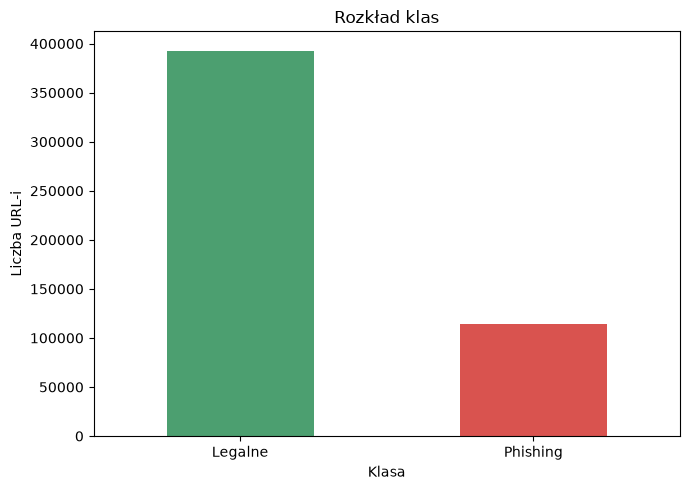

In [2]:
fig, ax = plt.subplots(figsize=(7, 5))
class_counts.plot(kind="bar", ax=ax, color=["#4C9F70", "#D9534F"])
ax.set(title="Rozkład klas", xlabel="Klasa", ylabel="Liczba URL-i")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(figures_dir / "class_distribution.png", dpi=150)
plt.show()

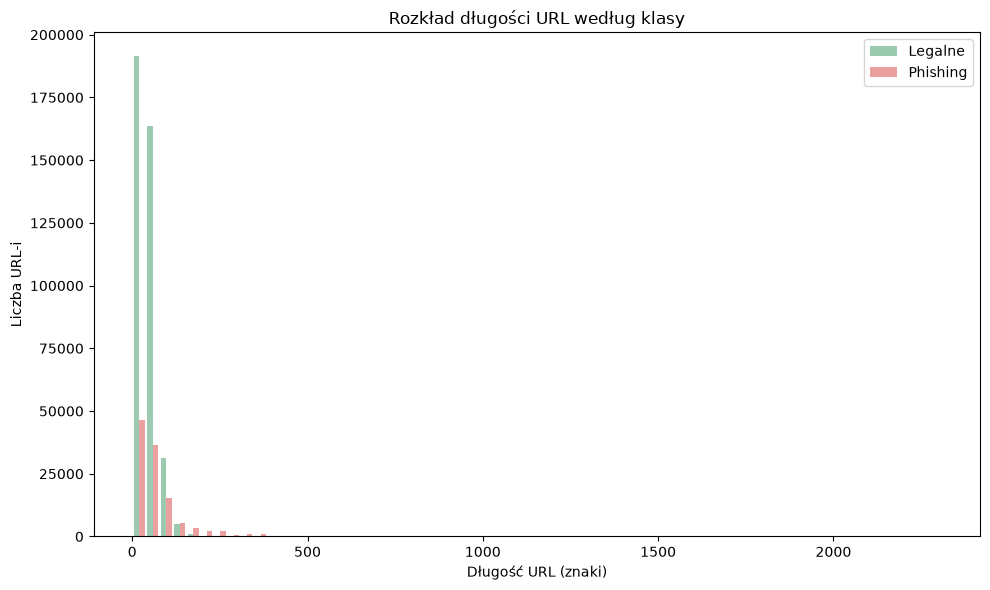

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
labels = ("Legalne", "Phishing")
histogram_data = [
    url_lengths.loc[url_lengths["Label"].eq(label), "Długość URL"].to_numpy()
    for label in labels
]
ax.hist(histogram_data, bins=60, alpha=0.55, label=labels, color=("#4C9F70", "#D9534F"))
ax.set(title="Rozkład długości URL według klasy", xlabel="Długość URL (znaki)", ylabel="Liczba URL-i")
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "url_length_by_class.png", dpi=150)
plt.show()

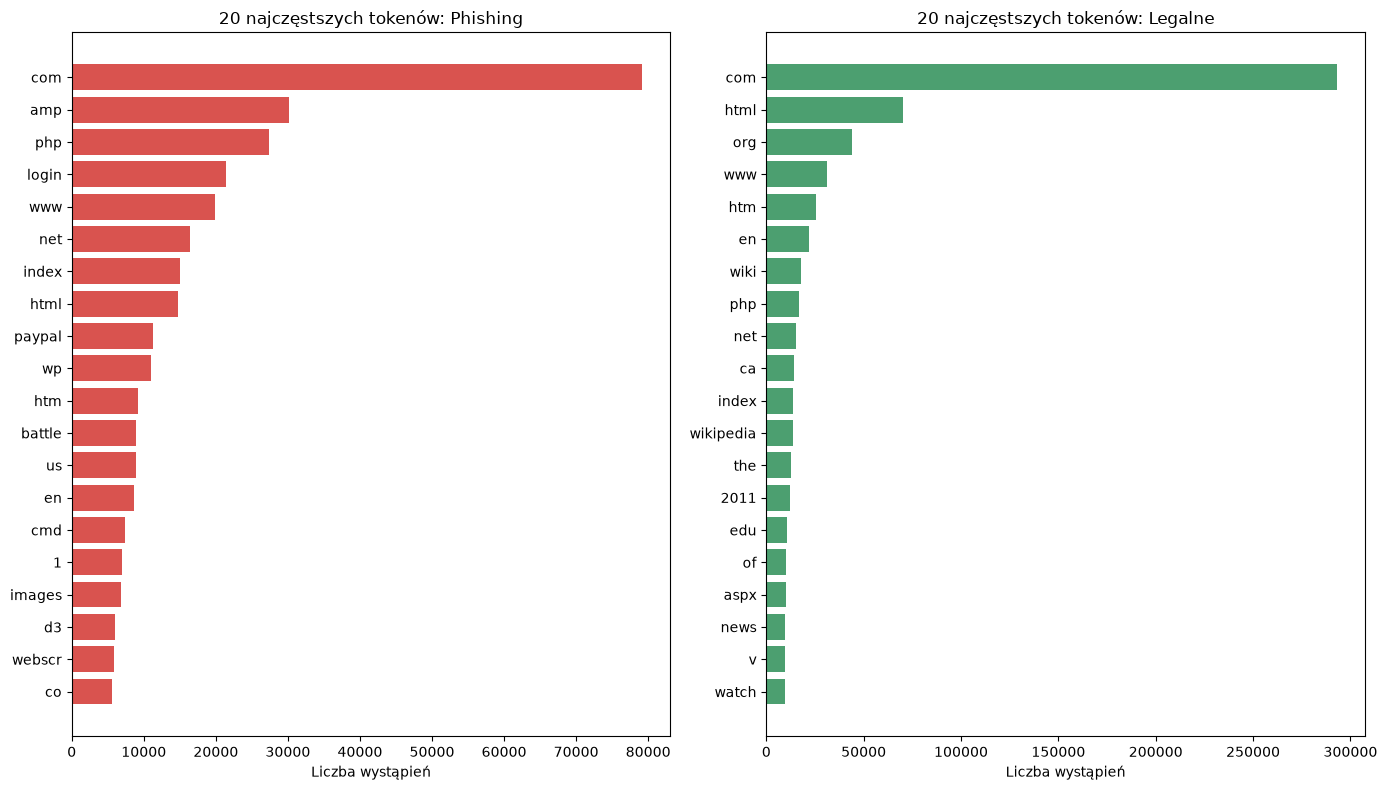

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, label, color in zip(axes, ("Phishing", "Legalne"), ("#D9534F", "#4C9F70")):
    class_tokens = top_tokens.loc[top_tokens["Label"].eq(label)].sort_values("Liczba")
    ax.barh(class_tokens["Token"], class_tokens["Liczba"], color=color)
    ax.set(title=f"20 najczęstszych tokenów: {label}", xlabel="Liczba wystąpień")
fig.tight_layout()
fig.savefig(figures_dir / "top_tokens_by_class.png", dpi=150)
plt.show()

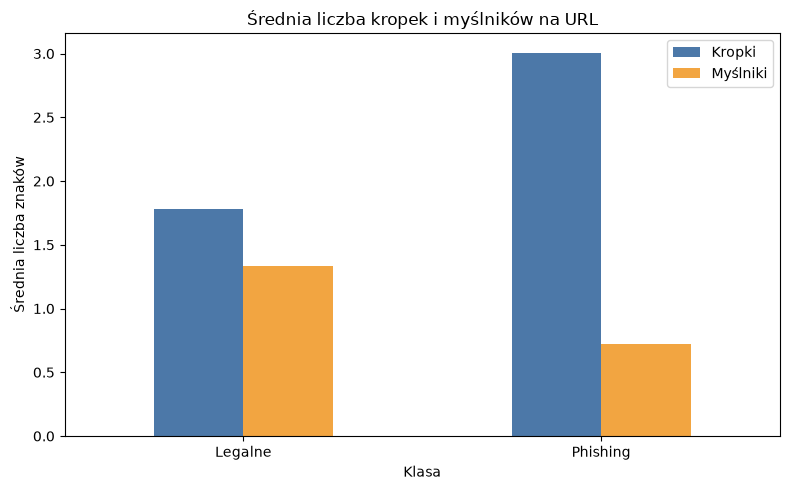

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
punctuation_counts.plot(kind="bar", ax=ax, color=["#4C78A8", "#F2A541"])
ax.set(title="Średnia liczba kropek i myślników na URL", xlabel="Klasa", ylabel="Średnia liczba znaków")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(figures_dir / "punctuation_by_class.png", dpi=150)
plt.show()